
# Chemical Process Data Quality and Exploratory Analysis

## Project Overview
This project explores a synthetic dataset representing batches from a hypothetical chemical production process. It demonstrates data inspection, quality assessment, cleaning, descriptive statistics, visualization, and correlation analysis using Python.

## Objectives
- Generate and inspect synthetic chemical process data.
- Identify missing values, duplicate records, and invalid data types.
- Clean the dataset and export the cleaned data.
- Explore product yield distributions and its relationship with temperature.
- Summarize findings while acknowledging the limitations of synthetic data.

## Tools and Libraries
- Python
- Pandas
- NumPy
- Matplotlib
- Jupyter Notebook

## Dataset Description
The dataset contains 200 synthetic batches with the following variables:
- `Batch_ID`: Unique batch identifier
- `Temperature_C`: Process temperature in degrees Celsius
- `Pressure_bar`: Process pressure in bar
- `Flow_Rate_L_min`: Flow rate in litres per minute
- `Reactant_Concentration_mol_L`: Reactant concentration in mol/L
- `Product_Yield_pct`: Product yield as a percentage

## Important Note
All data are synthetically generated for educational purposes. They do not represent measurements from a real chemical plant, and the relationships should not be interpreted as validated process behaviour.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Project environment is ready.")
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

Project environment is ready.
NumPy version: 2.3.5
Pandas version: 2.3.3


In [2]:
import numpy as np
import pandas as pd

# Generate reproducible synthetic data
rng = np.random.default_rng(42)

n = 200

temperature = rng.normal(80, 5, n)
pressure = rng.normal(5, 0.4, n)
flow_rate = rng.normal(12, 1.5, n)
concentration = rng.normal(2.0, 0.2, n)

# Illustrative relationship for learning only
yield_pct = (
    75
    + 0.25 * (temperature - 80)
    + 2.0 * (pressure - 5)
    + 3.0 * (concentration - 2.0)
    - 0.4 * (flow_rate - 12)
    + rng.normal(0, 2, n)
)

data = pd.DataFrame({
    "Batch_ID": [f"B{i:03d}" for i in range(1, n + 1)],
    "Temperature_C": temperature.round(2),
    "Pressure_bar": pressure.round(3),
    "Flow_Rate_L_min": flow_rate.round(2),
    "Reactant_Concentration_mol_L": concentration.round(3),
    "Product_Yield_pct": yield_pct.round(2)
})

data.head()

,Batch_ID,Temperature_C,Pressure_bar,Flow_Rate_L_min,Reactant_Concentration_mol_L,Product_Yield_pct
0,B001,81.52,5.135,11.73,2.103,74.38
1,B002,74.80,5.563,12.30,1.884,72.19
2,B003,83.75,5.036,13.23,2.255,76.97
3,B004,84.70,5.258,11.41,1.874,77.31
4,B005,70.24,4.180,12.78,1.873,72.80


In [3]:
from pathlib import Path

# Locate the project folder automatically
project_dir = Path.cwd().parent
data_dir = project_dir / "data"

# Create the data folder if it does not exist
data_dir.mkdir(parents=True, exist_ok=True)

# Save the synthetic dataset
csv_path = data_dir / "synthetic_chemical_process.csv"
data.to_csv(csv_path, index=False)

print("Dataset saved successfully.")
print("File location:", csv_path)
print("Dataset shape:", data.shape)

Dataset saved successfully.
File location: C:\Users\4xLam\OneDrive\Desktop\chemical-process-data-analysis\data\synthetic_chemical_process.csv
Dataset shape: (200, 6)


In [4]:
# Display the dataset dimensions
print("Number of rows and columns:", data.shape)

# Display column names
print("\nColumn names:")
print(data.columns.tolist())

# Display data types and non-null counts
print("\nDataset information:")
data.info()

# Display descriptive statistics
print("\nDescriptive statistics:")
data.describe()

Number of rows and columns: (200, 6)

Column names:
['Batch_ID', 'Temperature_C', 'Pressure_bar', 'Flow_Rate_L_min', 'Reactant_Concentration_mol_L', 'Product_Yield_pct']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Batch_ID                      200 non-null    object 
 1   Temperature_C                 200 non-null    float64
 2   Pressure_bar                  200 non-null    float64
 3   Flow_Rate_L_min               200 non-null    float64
 4   Reactant_Concentration_mol_L  200 non-null    float64
 5   Product_Yield_pct             200 non-null    float64
dtypes: float64(5), object(1)
memory usage: 9.5+ KB

Descriptive statistics:


,Temperature_C,Pressure_bar,Flow_Rate_L_min,Reactant_Concentration_mol_L,Product_Yield_pct
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,79.847650,5.008025,11.897700,1.992685,74.938300
std,4.409787,0.407831,1.524684,0.203546,2.496591
min,69.340000,3.973000,7.550000,1.487000,68.150000
25%,76.720000,4.721750,10.827500,1.842750,73.385000
50%,79.740000,5.024500,11.880000,2.002000,74.925000
75%,82.675000,5.255750,12.840000,2.127250,76.552500
max,94.570000,6.162000,15.900000,2.510000,82.060000


In [5]:
# Check missing values
print("Missing values per column:")
print(data.isnull().sum())

# Check duplicate rows
print("\nNumber of duplicate rows:")
print(data.duplicated().sum())

# Check duplicate batch IDs
print("\nNumber of duplicate Batch IDs:")
print(data["Batch_ID"].duplicated().sum())

# Check dataset dimensions
print("\nDataset dimensions:", data.shape)

Missing values per column:
Batch_ID                        0
Temperature_C                   0
Pressure_bar                    0
Flow_Rate_L_min                 0
Reactant_Concentration_mol_L    0
Product_Yield_pct               0
dtype: int64

Number of duplicate rows:
0

Number of duplicate Batch IDs:
0

Dataset dimensions: (200, 6)


In [6]:
# Create a separate copy for data-quality practice
messy_data = data.copy()

# Introduce a few missing values
messy_data.loc[5, "Temperature_C"] = np.nan
messy_data.loc[12, "Product_Yield_pct"] = np.nan

# Introduce one duplicate row
messy_data = pd.concat(
    [messy_data, messy_data.iloc[[0]]],
    ignore_index=True
)

# Introduce an invalid text value in a numeric column
messy_data["Pressure_bar"] = messy_data["Pressure_bar"].astype(object)
messy_data.loc[20, "Pressure_bar"] = "invalid"

print("Original dataset shape:", data.shape)
print("Practice dataset shape:", messy_data.shape)

print("\nMissing values:")
print(messy_data.isnull().sum())

print("\nDuplicate rows:", messy_data.duplicated().sum())
print("\nPressure data type:", messy_data["Pressure_bar"].dtype)

Original dataset shape: (200, 6)
Practice dataset shape: (201, 6)

Missing values:
Batch_ID                        0
Temperature_C                   1
Pressure_bar                    0
Flow_Rate_L_min                 0
Reactant_Concentration_mol_L    0
Product_Yield_pct               1
dtype: int64

Duplicate rows: 1

Pressure data type: object


In [7]:
# Create a separate copy for cleaning
clean_data = messy_data.copy()

# Convert Pressure_bar to numeric
# Invalid text values become NaN
clean_data["Pressure_bar"] = pd.to_numeric(
    clean_data["Pressure_bar"],
    errors="coerce"
)

# Remove duplicate rows
clean_data = clean_data.drop_duplicates()

# Count missing values before handling them
missing_before = clean_data.isnull().sum().sum()

# Remove rows containing missing values
clean_data = clean_data.dropna().copy()

# Save the cleaned dataset
clean_path = data_dir / "cleaned_chemical_process.csv"
clean_data.to_csv(clean_path, index=False)

print("Rows in original dataset:", len(data))
print("Rows in practice dataset:", len(messy_data))
print("Rows after cleaning:", len(clean_data))
print("Missing values before removal:", missing_before)
print("Missing values after cleaning:", clean_data.isnull().sum().sum())
print("Duplicate rows after cleaning:", clean_data.duplicated().sum())
print("Pressure data type after cleaning:", clean_data["Pressure_bar"].dtype)
print("Cleaned dataset saved to:", clean_path)

Rows in original dataset: 200
Rows in practice dataset: 201
Rows after cleaning: 197
Missing values before removal: 3
Missing values after cleaning: 0
Duplicate rows after cleaning: 0
Pressure data type after cleaning: float64
Cleaned dataset saved to: C:\Users\4xLam\OneDrive\Desktop\chemical-process-data-analysis\data\cleaned_chemical_process.csv


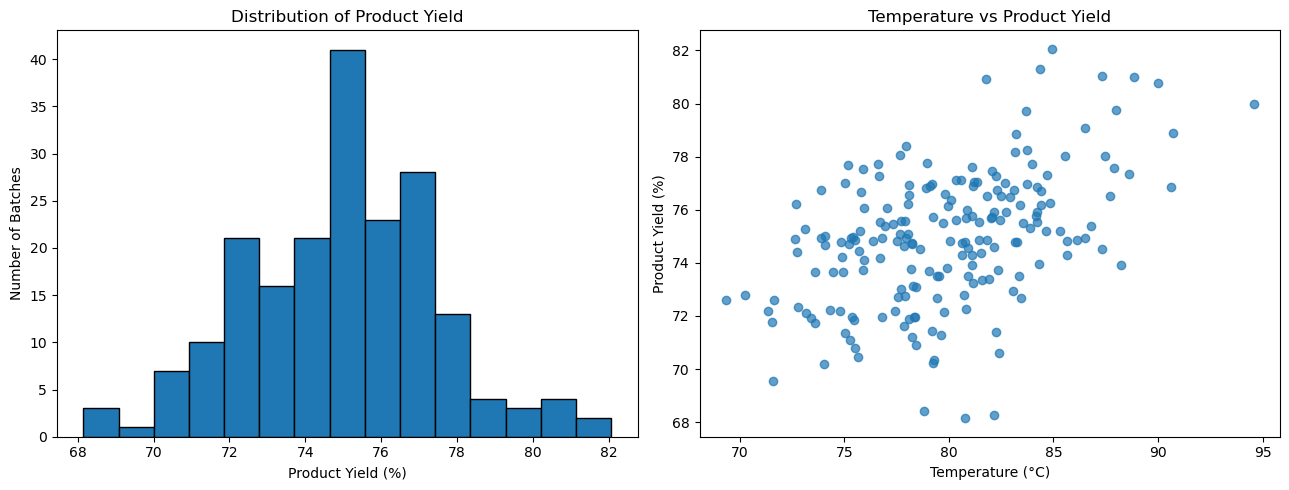

In [8]:
# Create two exploratory plots
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: Distribution of product yield
axes[0].hist(
    clean_data["Product_Yield_pct"],
    bins=15,
    edgecolor="black"
)
axes[0].set_title("Distribution of Product Yield")
axes[0].set_xlabel("Product Yield (%)")
axes[0].set_ylabel("Number of Batches")

# Plot 2: Temperature versus product yield
axes[1].scatter(
    clean_data["Temperature_C"],
    clean_data["Product_Yield_pct"],
    alpha=0.7
)
axes[1].set_title("Temperature vs Product Yield")
axes[1].set_xlabel("Temperature (°C)")
axes[1].set_ylabel("Product Yield (%)")

plt.tight_layout()
plt.show()


## Exploratory Data Analysis — Findings

### Product Yield Distribution
The synthetic product yield values are concentrated mainly between approximately 72% and 78%. The histogram shows variation across batches, with fewer observations at the lower and upper ends of the distribution.

### Temperature and Product Yield
The scatter plot suggests a generally positive association between temperature and product yield in the synthetic dataset. However, the observations show considerable variation, so temperature alone does not fully explain the yield values.

### Important Limitation
The dataset is synthetic, and the yield relationship was defined for educational purposes. These patterns should not be interpreted as experimentally validated chemical process behavior.


In [9]:
correlation = clean_data["Temperature_C"].corr(
    clean_data["Product_Yield_pct"]
)

print("Temperature-Yield correlation:", round(correlation, 3))

Temperature-Yield correlation: 0.477



### Correlation Analysis

The Pearson correlation coefficient between temperature and product yield is 0.477, indicating a moderate positive linear association in the synthetic dataset.

This result is consistent with the general upward trend observed in the scatter plot. However, correlation does not establish causation, and the relationship should not be generalized to real chemical processes because the dataset is synthetic.


## Conclusion

This project demonstrated a complete workflow for synthetic chemical process data analysis.

Key outcomes:
- Generated a reproducible dataset containing 200 synthetic batches.
- Inspected data dimensions, column types, and descriptive statistics.
- Introduced and identified missing values, a duplicate record, and an invalid numeric value in a separate practice dataset.
- Cleaned the practice dataset and verified the results.
- Visualized product yield distribution and its relationship with temperature.
- Calculated the Pearson correlation coefficient between temperature and product yield.

## Limitations

The dataset is synthetic and does not represent measurements from a real chemical plant. The observed relationships are illustrative and should not be used for process design or operational decisions.

## Future Improvements

- Analyze relationships between product yield and additional process variables.
- Investigate outliers and data quality rules.
- Apply regression models to the synthetic dataset.
- Repeat the analysis using a suitable real-world dataset when available.